# Proyecto 2 — Heap con imágenes

Página de referencia: <https://www.cs.usfca.edu/~galles/visualization/Heap.html>

En el capítulo 9 construyeron una clase `Heap` (min heap) cuyo arreglo queda **igual** al de la página después de cada operación. En este proyecto, a ese heap se le agrega la posibilidad de **tomar una imagen** de cómo queda constituido después de cada operación.

## 1. El heap

Use **su propia** clase `Heap` del cuaderno `ch09_construyendo_un_heap.ipynb`, con las mismas convenciones de la página:

- `self.arreglo[0]` es `-INF` (`float('-inf')`) y no hace parte del heap.
- La raíz está en `self.arreglo[1]`.
- Los hijos de la posición `i` están en `2*i` y `2*i + 1`.

Solo debe tener las tres operaciones de la página:

| Botón de la página | Método |
|---|---|
| **Insert** | `insert(valor)` |
| **Remove Smallest** | `remove_smallest()` |
| **BuildHeap** | `build_heap(lista)` |

Después de cada operación, `self.arreglo` debe quedar **igual** al arreglo de la página.

## 2. `build_heap(lista)`

Recibe una lista y deja `self.arreglo` convertido en un heap **igual** al que produce el botón **BuildHeap** de la página.

El botón BuildHeap de la página usa la lista `[31, 30, 29, ..., 1]`; con esa lista puede comparar su resultado.

## 3. La imagen

Cada una de las tres operaciones recibe un parámetro opcional `imagen`:

```python
H.insert(5, imagen=True)
H.remove_smallest(imagen=True)
H.build_heap([31, 30, 29, 28], imagen=True)
```

- Si `imagen=False` (valor por defecto), la operación no muestra nada.
- Si `imagen=True`, al terminar la operación se muestra una imagen del **árbol** del heap.

La imagen muestra **solo el estado final** del heap después de la operación (no los pasos intermedios ni una animación):

- cada nodo con su valor;
- las aristas entre cada nodo y sus hijos;
- la raíz arriba y cada nivel debajo del anterior, con los hijos izquierdos a la izquierda y los derechos a la derecha, como el árbol de la página.

El `-INF` de la posición 0 no aparece en la imagen.

## 4. Ejemplo

```python
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)    # imagen del heap con 4, 10 y 7
H.remove_smallest(imagen=True)
```

La primera imagen debe mostrar `4` en la raíz con hijos `10` y `7`, como la página después de insertar 10, 4 y 7.

## 5. Su solución en `heap.py`

La clase `Heap` debe quedar en un archivo **`heap.py`** (con ese nombre exacto) en su repositorio, en

```
student_work/Proyecto2/heap.py
```

para luego **importarla**:

```python
from heap import Heap
```

Escriba su clase en la celda de abajo. La primera línea, `%%writefile heap.py`, **no** ejecuta el código: guarda el contenido de la celda en el archivo `heap.py`, en la misma carpeta de este cuaderno. Cada vez que modifique su clase, vuelva a ejecutar esa celda para sobrescribir el archivo.

- El archivo debe poder importarse sin errores: no deje pruebas sueltas en él. Si quiere dejar pruebas dentro del `.py`, póngalas debajo de `if __name__ == "__main__":`.
- `from heap import Heap` no toma sus cambios hasta que reinicie el kernel; para releer el archivo sin reiniciar use `importlib.reload` como en la celda de prueba.
- No olvide hacer *commit* y *push* de `heap.py` a su repositorio.

In [1]:
%%writefile heap.py
import matplotlib.pyplot as plt


class Heap:

    def __init__(self):
        self.arreglo = [float('-inf')]

    def insert(self, valor, imagen=False):
        self.arreglo.append(valor)
        ih = len(self.arreglo) - 1
        hijo = self.arreglo[ih]
        ip = ih // 2
        padre = self.arreglo[ip]
        while hijo < padre:
            self.arreglo[ih], self.arreglo[ip] = self.arreglo[ip], self.arreglo[ih]
            ih = ip
            ip = ih // 2
            hijo = self.arreglo[ih]
            padre = self.arreglo[ip]
        if imagen:
            self.dibujar()

    def _hundir(self, n):
        largo = len(self.arreglo)
        hijo_izq = 2 * n
        hijo_der = 2 * n + 1
        mas_peque = n

        # Buscar si el hijo izquierdo es menor
        if hijo_izq < largo and self.arreglo[hijo_izq] < self.arreglo[mas_peque]:
            mas_peque = hijo_izq

        # Buscar si el hijo derecho es menor
        if hijo_der < largo and self.arreglo[hijo_der] < self.arreglo[mas_peque]:
            mas_peque = hijo_der

        # Si el menor no es el nodo actual, intercambiamos y seguimos bajando
        if mas_peque != n:
            self.arreglo[n], self.arreglo[mas_peque] = self.arreglo[mas_peque], self.arreglo[n]
            self._hundir(mas_peque)

    def remove_smallest(self, imagen=False):
        if len(self.arreglo) <= 1:
            if imagen:
                self.dibujar()
            return None

        val_min = self.arreglo[1]

        ultimo_elemento = self.arreglo.pop()

        if len(self.arreglo) > 1:
            self.arreglo[1] = ultimo_elemento
            self._hundir(1)

        if imagen:
            self.dibujar()
        return val_min

    def build_heap(self, lista, imagen=False):
        self.arreglo = [float('-inf')]
        for x in lista:
            self.arreglo.append(x)
        ultimo = len(self.arreglo) - 1
        i = ultimo // 2
        while i >= 1:
            self._hundir(i)
            i = i - 1

        if imagen:
            self.dibujar()

    def dibujar(self):
        cantidad = len(self.arreglo) - 1
        plt.figure(figsize=(10, 4))
        plt.axis('off')

        if cantidad == 0:
            plt.text(0.5, 0.5, 'Heap vacio', ha='center', fontsize=14)
            plt.show()
            return

        # Primero se calcula dónde va cada nodo
        xs = {}
        ys = {}
        for i in range(1, cantidad + 1):
            nivel = 0
            while 2 ** (nivel + 1) <= i:
                nivel = nivel + 1
            puesto = i - 2 ** nivel               # qué lugar ocupa dentro de su nivel
            xs[i] = (puesto + 0.5) / 2 ** nivel   # izquierda a derecha
            ys[i] = -nivel                        # cada nivel más abajo

        # Las aristas: cada nodo (menos la raíz) se une con su padre
        for i in range(2, cantidad + 1):
            padre = i // 2
            plt.plot([xs[padre], xs[i]], [ys[padre], ys[i]], color='black', zorder=1)

        # Los nodos con su valor
        for i in range(1, cantidad + 1):
            plt.scatter(xs[i], ys[i], s=700, color='white', edgecolors='blue', zorder=2)
            plt.text(xs[i], ys[i], str(self.arreglo[i]), ha='center', va='center', zorder=3)

        # Márgenes para que no se corten los círculos de las orillas
        plt.xlim(-0.05, 1.05)
        plt.ylim(min(ys.values()) - 0.5, 0.5)
        plt.show()


Writing heap.py


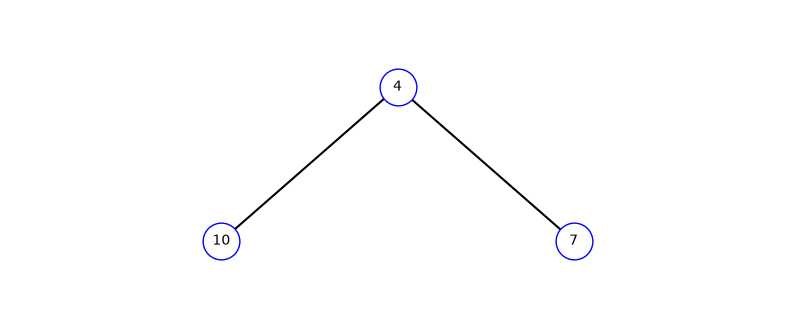

In [2]:
import importlib
import heap
importlib.reload(heap)         
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)

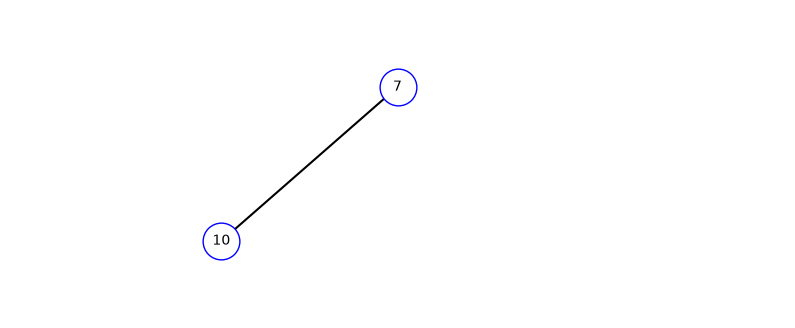

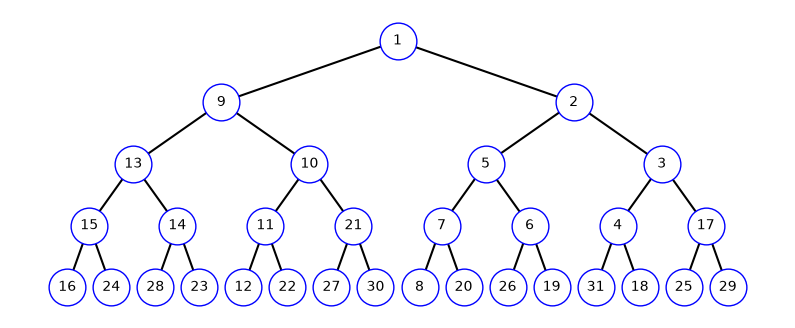

[-inf, 1, 9, 2, 13, 10, 5, 3, 15, 14, 11, 21, 7, 6, 4, 17, 16, 24, 28, 23, 12, 22, 27, 30, 8, 20, 26, 19, 31, 18, 25, 29]


In [3]:
H.remove_smallest(imagen=True)  

H.build_heap(list(range(31, 0, -1)), imagen=True)
print(H.arreglo)